# Test2–Test4 concordance

Compare the automated DGIdb-based evaluations in the two `02_analysis.ipynb` notebooks. Results are recomputed from the original CSVs against the same curated truth workbook, across all genes. Run this notebook from its own directory. No human corrections are applied and no workbooks are exported.

**Precision, candidate-based recall, and F1** use only generated PMID–drug–gene candidates, matching the primary scoring in test2 and test4. Truth interactions without a generated prediction do not contribute to that recall denominator. **End-to-end recovery** measures positively predicted truth interactions out of the entire truth set, including missing candidates. DGIdb-unmatched positive predictions are labeled false positives for this comparison; this is not a manual judgment of their biological validity.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

KEYS = ["pmid", "drug", "gene"]
RUN_FILES = {
    "test2": Path("../test2_curated_dgidb/2026-06-29-interaction_classifications-rohit.csv"),
    "test4": Path("interaction_classifications-rohit-qwen3-14b.csv"),
}
TRUTH_FILE = Path("../../../data/2026-06-29-test2-RohitList-wText.xlsx")

## Load and validate inputs

Names are matched exactly after uppercasing and trimming whitespace; synonyms are not resolved. Incomplete prediction keys (such as skipped rows) are excluded and counted below. Predictions for complete keys must be Boolean. Identical repeated classifications are consolidated, preserving distinct evidence text; conflicting classifications for the same key raise an error. Missing predictions remain separate from explicit negative predictions.

In [2]:
def require_columns(df, columns, label):
    missing = set(columns) - set(df.columns)
    if missing:
        raise ValueError(f"{label}: missing required columns {sorted(missing)}")


def normalize_keys(df):
    df = df.copy()
    for column in ["drug", "gene"]:
        df[column] = df[column].astype("string").str.upper().str.strip().replace("", pd.NA)
    df["pmid"] = pd.to_numeric(df["pmid"], errors="raise").astype("Int64")
    return df


def validate_predictions(raw, label):
    require_columns(raw, KEYS + ["interaction", "evidence"], label)
    normalized = normalize_keys(raw)
    valid = normalized.dropna(subset=KEYS).copy()
    tokens = valid["interaction"].astype("string").str.strip().str.lower()
    invalid = tokens.isna() | ~tokens.isin(["true", "false"])
    if invalid.any():
        raise ValueError(f"{label}: non-Boolean predictions at rows {valid.index[invalid].tolist()}")
    valid["predicted"] = tokens.map({"true": True, "false": False}).astype("boolean")
    conflicts = valid.groupby(KEYS)["predicted"].nunique()
    if conflicts.gt(1).any():
        raise ValueError(f"{label}: conflicting predictions for {conflicts[conflicts.gt(1)].index.tolist()}")
    evidence = valid.groupby(KEYS, sort=False)["evidence"].agg(
        lambda values: "\n\n".join(dict.fromkeys(values.dropna().astype(str)))
    ).reset_index()
    pairs = valid[KEYS + ["predicted"]].drop_duplicates().merge(
        evidence, on=KEYS, validate="one_to_one"
    )
    audit = {
        "Input rows": len(raw),
        "Incomplete-key rows excluded": len(raw) - len(valid),
        "Repeated classifications consolidated": len(valid) - len(pairs),
        "Evaluated candidates": len(pairs),
        "PMIDs with candidates": pairs["pmid"].nunique(),
    }
    return pairs, audit


truth_raw = pd.read_excel(TRUTH_FILE)
require_columns(truth_raw, ["pmid", "drug_name", "gene_name", "context"], "truth workbook")
truth_normalized = normalize_keys(truth_raw.rename(columns={"drug_name": "drug", "gene_name": "gene"}))
truth_pairs = truth_normalized.dropna(subset=KEYS)[KEYS + ["context"]].drop_duplicates(KEYS)
truth_set = set(truth_pairs[KEYS].itertuples(index=False, name=None))
if not truth_set:
    raise ValueError("The truth workbook has no complete interaction keys")

runs, audits = {}, {}
for run, path in RUN_FILES.items():
    runs[run], audits[run] = validate_predictions(pd.read_csv(path), run)
display(pd.DataFrame(audits))
print(f"Shared truth set: {len(truth_pairs)} interactions across {truth_pairs['pmid'].nunique()} PMIDs")

,test2,test4
Input rows,206,206
Incomplete-key rows excluded,6,6
Repeated classifications consolidated,0,0
Evaluated candidates,200,200
PMIDs with candidates,94,94


Shared truth set: 100 interactions across 100 PMIDs


## Headline metrics

Rate differences are **test4 minus test2 in percentage points**. Count differences are raw counts.

,test2,test4,Test4 − test2,Difference unit
Evaluated candidates,200,200,+0.00,count
TP,84,84,+0.00,count
FP,48,47,-1.00,count
TN,68,69,+1.00,count
FN,0,0,+0.00,count
Precision,63.64%,64.12%,+0.49,percentage points
Candidate-based recall,100.00%,100.00%,+0.00,percentage points
F1,77.78%,78.14%,+0.36,percentage points
Recovered truth interactions,84,84,+0.00,count
Total truth interactions,100,100,+0.00,count


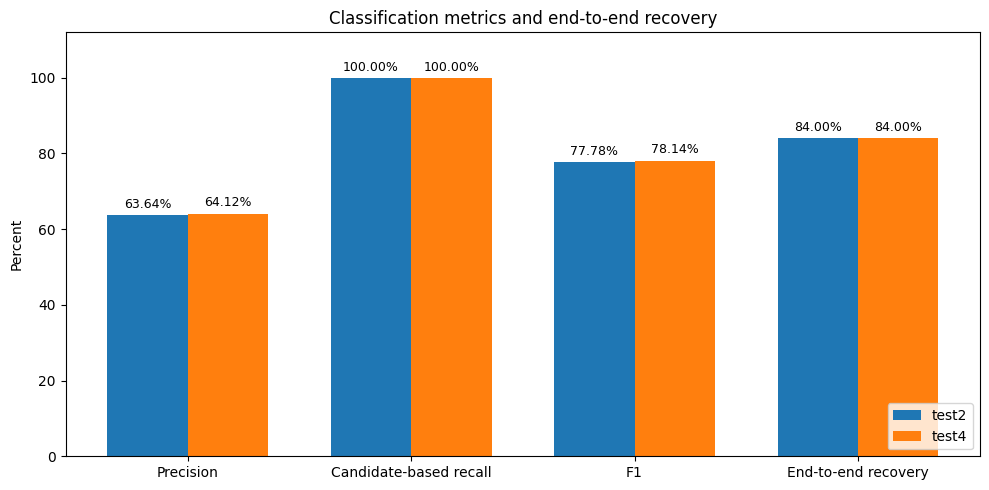

In [3]:
def score_candidates(pairs, truth_set):
    is_truth = pd.Series(
        [key in truth_set for key in pairs[KEYS].itertuples(index=False, name=None)],
        index=pairs.index, dtype=bool,
    )
    positive = pairs["predicted"].astype(bool)
    tp = int((is_truth & positive).sum())
    fp = int((~is_truth & positive).sum())
    tn = int((~is_truth & ~positive).sum())
    fn = int((is_truth & ~positive).sum())
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    return {
        "Evaluated candidates": len(pairs), "TP": tp, "FP": fp, "TN": tn, "FN": fn,
        "Precision": precision, "Candidate-based recall": recall, "F1": f1,
        "Recovered truth interactions": tp,
        "Total truth interactions": len(truth_set),
        "End-to-end recovery": tp / len(truth_set) if truth_set else np.nan,
    }


metrics = pd.DataFrame({run: score_candidates(pairs, truth_set) for run, pairs in runs.items()})
rate_metrics = ["Precision", "Candidate-based recall", "F1", "End-to-end recovery"]
comparison = metrics.copy()
comparison["Test4 − test2"] = comparison["test4"] - comparison["test2"]
comparison["Difference unit"] = "count"
comparison.loc[rate_metrics, "Test4 − test2"] *= 100
comparison.loc[rate_metrics, "Difference unit"] = "percentage points"
formatted = comparison.copy().astype(object)
for metric in comparison.index:
    for run in RUN_FILES:
        value = comparison.loc[metric, run]
        formatted.loc[metric, run] = f"{value:.2%}" if metric in rate_metrics else f"{value:.0f}"
    formatted.loc[metric, "Test4 − test2"] = f"{comparison.loc[metric, 'Test4 − test2']:+.2f}"
display(formatted)

fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(rate_metrics))
for offset, run in [(-0.18, "test2"), (0.18, "test4")]:
    bars = ax.bar(x + offset, metrics.loc[rate_metrics, run] * 100, width=0.36, label=run)
    ax.bar_label(bars, fmt="%.2f%%", padding=3, fontsize=9)
ax.set_xticks(x, rate_metrics)
ax.set_ylim(0, 112)
ax.set_ylabel("Percent")
ax.set_title("Classification metrics and end-to-end recovery")
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

## Agreement on individual candidates

Candidate overlap uses the union of complete PMID–drug–gene keys. Classification agreement and Cohen’s kappa use **shared candidates only**. Kappa adjusts for agreement expected from each run's positive/negative proportions; it is undefined if there are no shared candidates or expected agreement is 100%. Neither run is treated as ground truth in the agreement matrix.

,Value
Candidate union,200.0
Shared candidates,200.0
Test2-only candidates,0.0
Test4-only candidates,0.0
Candidate intersection / union,1.0


,Value
Agreeing classifications,173.000000
Disagreeing classifications,27.000000
Classification agreement,0.865000
Cohen's kappa,0.700266


Test4,Interaction,No interaction
Test2,,
Interaction,118,14
No interaction,13,55


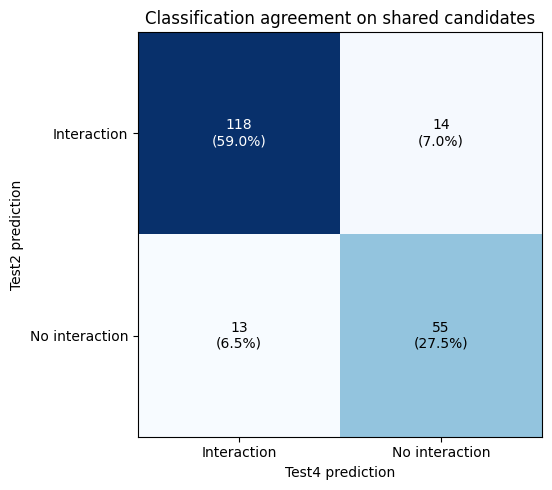

In [4]:
aligned = runs["test2"].rename(columns={"predicted": "test2_predicted", "evidence": "test2_evidence"}).merge(
    runs["test4"].rename(columns={"predicted": "test4_predicted", "evidence": "test4_evidence"}),
    on=KEYS, how="outer", indicator="candidate_membership", validate="one_to_one",
)
shared = aligned.loc[aligned["candidate_membership"] == "both"].copy()
shared_count = len(shared)
agreeing = int((shared["test2_predicted"] == shared["test4_predicted"]).sum())
agreement_rate = agreeing / shared_count if shared_count else np.nan
p2 = float(shared["test2_predicted"].mean()) if shared_count else np.nan
p4 = float(shared["test4_predicted"].mean()) if shared_count else np.nan
expected_agreement = p2 * p4 + (1 - p2) * (1 - p4)
kappa = (agreement_rate - expected_agreement) / (1 - expected_agreement) if shared_count and not np.isclose(expected_agreement, 1.0) else np.nan

overlap = pd.Series({
    "Candidate union": len(aligned),
    "Shared candidates": shared_count,
    "Test2-only candidates": int((aligned["candidate_membership"] == "left_only").sum()),
    "Test4-only candidates": int((aligned["candidate_membership"] == "right_only").sum()),
    "Candidate intersection / union": shared_count / len(aligned) if len(aligned) else np.nan,
})
display(overlap.to_frame("Value"))
display(pd.Series({
    "Agreeing classifications": agreeing,
    "Disagreeing classifications": shared_count - agreeing,
    "Classification agreement": agreement_rate,
    "Cohen's kappa": kappa,
}).to_frame("Value"))

agreement_matrix = pd.DataFrame(
    [[int(((shared["test2_predicted"] == row) & (shared["test4_predicted"] == col)).sum())
      for col in [True, False]] for row in [True, False]],
    index=pd.Index(["Interaction", "No interaction"], name="Test2"),
    columns=pd.Index(["Interaction", "No interaction"], name="Test4"),
)
display(agreement_matrix)
fig, ax = plt.subplots(figsize=(6, 5))
ax.imshow(agreement_matrix.to_numpy(), cmap="Blues")
ax.set_xticks([0, 1], agreement_matrix.columns)
ax.set_yticks([0, 1], agreement_matrix.index)
ax.set_xlabel("Test4 prediction")
ax.set_ylabel("Test2 prediction")
ax.set_title("Classification agreement on shared candidates")
for (row, col), count in np.ndenumerate(agreement_matrix.to_numpy()):
    percentage = count / shared_count if shared_count else 0
    ax.text(col, row, f"{count}\n({percentage:.1%})", ha="center", va="center",
            color="white" if count > agreement_matrix.to_numpy().max() * 0.55 else "black")
fig.tight_layout()
plt.show()

unshared_candidates = aligned.loc[aligned["candidate_membership"] != "both"].copy()
if len(unshared_candidates):
    print("Candidates present in only one run (missing predictions are not negatives):")
    display(unshared_candidates)

## Classification disagreements

Truth membership is based on exact normalized keys in the shared DGIdb truth set. Evidence is displayed from both runs.

In [5]:
disagreements = shared.loc[shared["test2_predicted"] != shared["test4_predicted"]].copy()
disagreements["in_truth"] = [
    key in truth_set for key in disagreements[KEYS].itertuples(index=False, name=None)
]
disagreements = disagreements[KEYS + ["in_truth", "test2_predicted", "test4_predicted", "test2_evidence", "test4_evidence"]].sort_values(KEYS)
with pd.option_context("display.max_rows", None, "display.max_colwidth", None):
    display(disagreements)

,pmid,drug,gene,in_truth,test2_predicted,test4_predicted,test2_evidence,test4_evidence
8,9632354,PURINE,TOP1,False,False,True,,"The N3 position of the 5' terminal purine of the cleaved DNA strand is readily alkylated by 7-chloromethyl 10,11-methylenedioxy CPT"
9,9632354,TYROSINE,TOP1,False,True,False,,
15,11217909,CAPSAICIN,ACE,False,False,True,,The cough threshold was determined by the concentration of inhaled capsaicin causing two or more coughs.
22,18332269,CHOLESTEROL,HMGCR,False,True,False,,
25,18559695,CHOLESTEROL,HMGCR,False,False,True,,"Variation in the production of an HMGCR isoform with reduced statin sensitivity is a determinant of interindividual differences in low-density lipoprotein cholesterol, apolipoprotein B, and triglyceride response to statin treatment."
37,20921462,IRINOTECAN HYDROCHLORIDE,KRAS,False,True,False,,
41,20921465,OXALIPLATIN,KRAS,False,False,True,,Results were prospectively analyzed on an intent-to-treat basis by tumor KRAS status.
44,21783417,CARBOPLATIN,EGFR,False,True,False,,
46,21783417,GEMCITABINE,EGFR,False,True,False,,
50,22285168,CARBOPLATIN,EGFR,False,True,False,,


## Agreement on truth interaction recovery

Each truth interaction is recovered only if its exact PMID–drug–gene key has a positive prediction. Missing candidates count as unrecovered here, while their prediction values remain missing in the detail table. A negative prediction also counts as unrecovered.

In [6]:
recovery = truth_pairs.copy()
for run in RUN_FILES:
    recovery = recovery.merge(
        runs[run][KEYS + ["predicted"]].rename(columns={"predicted": f"{run}_predicted"}),
        on=KEYS, how="left", validate="one_to_one",
    )
    recovery[f"{run}_recovered"] = recovery[f"{run}_predicted"].fillna(False).astype(bool)
r2, r4 = recovery["test2_recovered"], recovery["test4_recovered"]
recovery["Recovery category"] = np.select(
    [r2 & r4, r2 & ~r4, ~r2 & r4],
    ["Recovered by both", "Test2 only", "Test4 only"], default="Recovered by neither",
)
category_order = ["Recovered by both", "Test2 only", "Test4 only", "Recovered by neither"]
recovery_summary = recovery["Recovery category"].value_counts().reindex(category_order, fill_value=0).to_frame("Interactions")
recovery_summary["Share of truth set"] = recovery_summary["Interactions"] / len(recovery)
display(recovery_summary)
recovery_agreement = (r2 == r4).mean()
print(f"Recovery-status agreement: {recovery_agreement:.1%} across {len(recovery)} truth interactions")

missed_truth = recovery.loc[~(r2 & r4)].sort_values(["Recovery category"] + KEYS)
print("Truth interactions missed by at least one run (context included):")
with pd.option_context("display.max_rows", None, "display.max_colwidth", None):
    display(missed_truth)

assert agreement_matrix.to_numpy().sum() == shared_count
assert recovery_summary["Interactions"].sum() == len(truth_set)
for run in RUN_FILES:
    assert recovery[f"{run}_recovered"].sum() == metrics.loc["Recovered truth interactions", run]

,Interactions,Share of truth set
Recovery category,,
Recovered by both,84,0.84
Test2 only,0,0.00
Test4 only,0,0.00
Recovered by neither,16,0.16


Recovery-status agreement: 100.0% across 100 truth interactions
Truth interactions missed by at least one run (context included):


,pmid,drug,gene,context,test2_predicted,test2_recovered,test4_predicted,test4_recovered,Recovery category
53,15236790,TRASTUZUMAB,ERBB2,"Human papillomavirus (HPV) type 16 is causally associated with a subset of oral cancers, predominantly those cancers arising in the oropharynx (OP). Increased HPV16 E6 and E7 oncogene expressions are responsible for the malignant transmission in these cancers. ErbB-2 is the family member most closely implicated in human cancer, where it is overexpressed in about 30% of carcinomas including head and neck squamous cell carcinoma. Coexpressions of E6/E7 and ErbB-2 downregulate E-cadherin and catenin expression, therefore induces metastatic process. Trastuzumab is a humanized monoclonal antibody that recognizes the ErbB-2 protein receptor and breakthrough in the treatment of metastatic breast cancer in combination with chemotherapeutic agents. This antibody is also in clinical testing for adjuvant treatment of breast cancer. We propose that trastuzumab as an adjuvant treatment may decrease process of tumor metastasis in oropharyngeal cancer patients who completed primary treatment (surgery and/or radiotherapy) and show expression of both HPV16 E6/E7 and erbB-2 oncoproteins. In vitro and in vivo studies with trastuzumab in these subgroup of patients may support our hypothesis.",<NA>,False,<NA>,False,Recovered by neither
43,20921462,PANITUMUMAB,KRAS,"PURPOSE: Panitumumab is a fully human anti-epidermal growth factor receptor (EGFR) monoclonal antibody that improves progression-free survival (PFS) in chemotherapy-refractory metastatic colorectal cancer (mCRC). This trial evaluated the efficacy and safety of panitumumab plus fluorouracil, leucovorin, and irinotecan (FOLFIRI) compared with FOLFIRI alone after failure of initial treatment for mCRC by tumor KRAS status.\nPATIENTS AND METHODS: Patients with mCRC, one prior chemotherapy regimen for mCRC, Eastern Cooperative Oncology Group performance status 0 to 2, and available tumor tissue for biomarker testing were randomly assigned 1:1 to panitumumab 6.0 mg/kg plus FOLFIRI versus FOLFIRI every 2 weeks. The coprimary end points of PFS and overall survival (OS) were independently tested and prospectively analyzed by KRAS status.\nRESULTS: From June 2006 to March 2008, 1,186 patients were randomly assigned 1:1 and received treatment. KRAS status was available for 91% of patients: 597 (55%) with wild-type (WT) KRAS tumors, and 486 (45%) with mutant (MT) KRAS tumors. In the WT KRAS subpopulation, when panitumumab was added to chemotherapy, a significant improvement in PFS was observed (hazard ratio [HR] = 0.73; 95% CI, 0.59 to 0.90; P = .004); median PFS was 5.9 months for panitumumab-FOLFIRI versus 3.9 months for FOLFIRI. A nonsignificant trend toward increased OS was observed; median OS was 14.5 months versus 12.5 months, respectively (HR = 0.85, 95% CI, 0.70 to 1.04; P = .12); response rate was improved to 35% versus 10% with the addition of panitumumab. In patients with MT KRAS, there was no difference in efficacy. Adverse event rates were generally comparable across arms with the exception of known toxicities associated with anti-EGFR therapy.\nCONCLUSION: Panitumumab plus FOLFIRI significantly improved PFS and is well-tolerated as second-line treatment in patients with WT KRAS mCRC.",<NA>,False,<NA>,False,Recovered by neither
41,20921465,PANITUMUMAB,KRAS,"PURPOSE: Panitumumab, a fully human anti-epidermal growth factor receptor (EGFR) monoclonal antibody that improves progression-free survival (PFS), is approved as monotherapy for patients with chemotherapy-refractory metastatic colorectal cancer (mCRC). The Panitumumab Randomized Trial in Combination With Chemotherapy for Metastatic Colorectal Cancer to Determine Efficacy (PRIME) was designed to evaluate the efficacy and safety of panitumumab plus infusional fluorouracil, leucovorin, and oxaliplatin (FOLFOX4) versus FOLFOX4 alone as initial treatment for mCRC.\nPATIENTS AND METHODS: In this multicen

## Interpretation

Compare metric differences alongside classification and recovery agreement. Similar headline scores can hide different decisions on individual candidates; identical recovery rates can also hide different recovered interactions. The paired tables above distinguish these cases.

In [7]:
display(Markdown(
    f"- Precision: **{metrics.loc['Precision', 'test2']:.2%}** (test2) versus "
    f"**{metrics.loc['Precision', 'test4']:.2%}** (test4), a change of "
    f"**{comparison.loc['Precision', 'Test4 − test2']:+.2f} percentage points**.\n"
    f"- Candidate-based recall: **{metrics.loc['Candidate-based recall', 'test2']:.2%}** versus "
    f"**{metrics.loc['Candidate-based recall', 'test4']:.2%}**.\n"
    f"- End-to-end recovery: **{int(r2.sum())}/{len(recovery)}** versus "
    f"**{int(r4.sum())}/{len(recovery)}**; "
    f"**{int((r2 & r4).sum())}** truth interactions recovered by both.\n"
    f"- Shared-candidate classification agreement: **{agreement_rate:.2%}** "
    f"({agreeing}/{shared_count}); **{len(disagreements)}** disagreements; "
    f"Cohen’s kappa **{kappa:.3f}**.\n"
    f"- Truth recovery-status agreement: **{recovery_agreement:.2%}**."
))

- Precision: **63.64%** (test2) versus **64.12%** (test4), a change of **+0.49 percentage points**.
- Candidate-based recall: **100.00%** versus **100.00%**.
- End-to-end recovery: **84/100** versus **84/100**; **84** truth interactions recovered by both.
- Shared-candidate classification agreement: **86.50%** (173/200); **27** disagreements; Cohen’s kappa **0.700**.
- Truth recovery-status agreement: **100.00%**.